In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from mecbench.instances.synthetic import make_tree_instance
instance = make_tree_instance(3, 1)

In [2]:
from mecbench.solvers.exact.ilp_arc import Solver as ilp_arc_Solver
from mecbench.solvers.relaxations.lp_arc import Solver as lp_arc_Solver
from mecbench.solvers.exact.ilp_path import Solver as ilp_path_Solver
from mecbench.solvers.relaxations.lp_path_latency_tightened import Solver as lp_path_strong_latency_Solver

mecbench.solvers = {'ILP':ilp_arc_Solver, 'Relaxation':lp_arc_Solver, 'ILP-Path':ilp_path_Solver, 'Relaxation Enforced Latency':lp_path_strong_latency_Solver}

for sol_name, Solver in mecbench.solvers.items():
    sol = Solver(instance)
    sol.run()
    print(f'Solver {sol_name} - Objective value: {sol.score} - Time: {sol.runtime}')


Solver ILP - Objective value: 21.0 - Time: 0.7871057987213135
Solver Relaxation - Objective value: 21.0 - Time: 0.04893016815185547
Solver ILP-Path - Objective value: 21.0 - Time: 1.2966296672821045
Solver Relaxation Enforced Latency - Objective value: 21.0 - Time: 0.1484682559967041


50
100
150


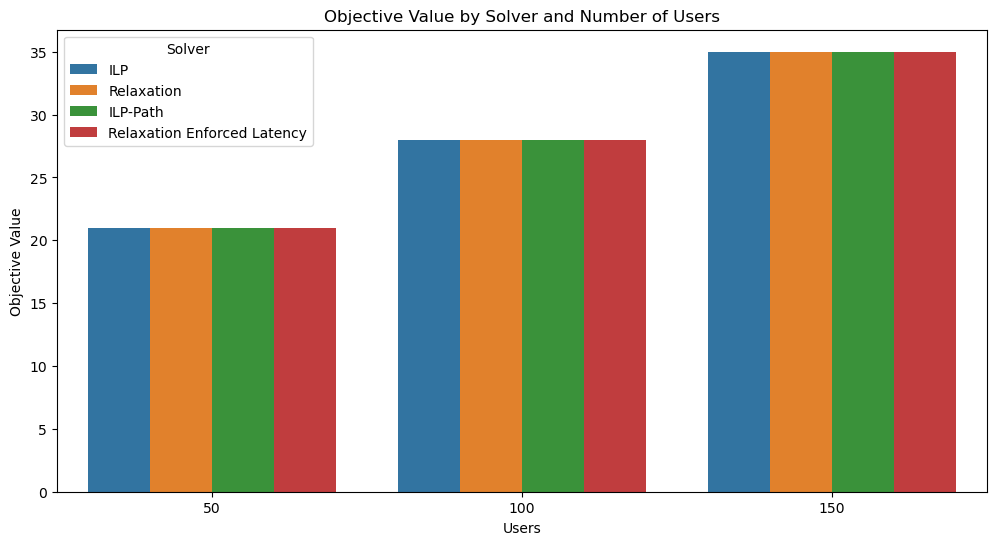

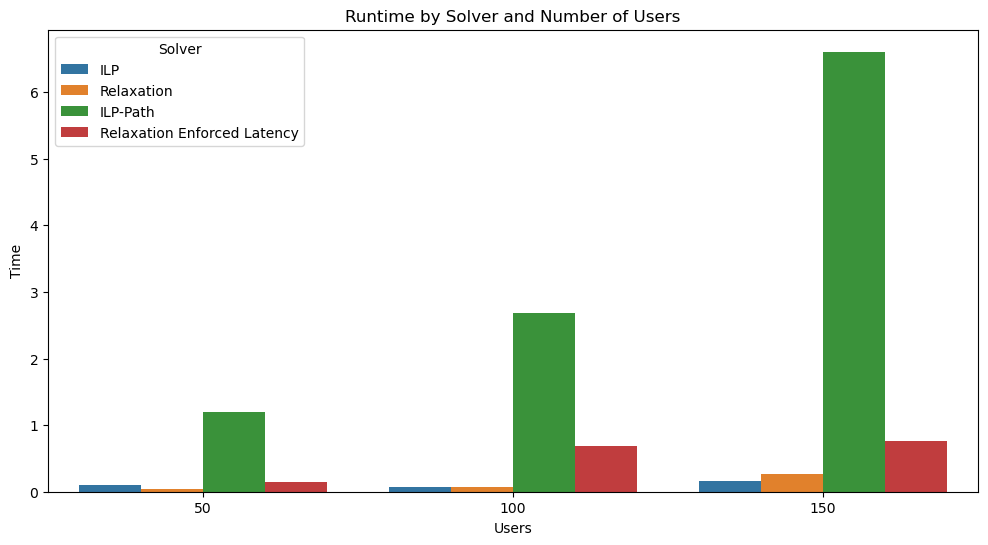

In [ ]:
import pandas as pd
import seaborn as sns
import numpy as np
from mecbench.instances.synthetic import make_tree_instance
from mecbench.solvers.exact.ilp_arc import Solver as ilp_arc_Solver
from mecbench.solvers.relaxations.lp_arc import Solver as lp_arc_Solver
from mecbench.solvers.exact.ilp_path import Solver as ilp_path_Solver
from mecbench.solvers.relaxations.lp_path_latency_tightened import Solver as lp_path_strong_latency_Solver

import matplotlib.pyplot as plt
import os
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"


# Create instances with 50, 100, and 150 users
instances = {
    50: make_tree_instance(50, 1),
    100: make_tree_instance(100, 1),
    150: make_tree_instance(150, 1)
}

results = []


mecbench.solvers = {'ILP': ilp_arc_Solver, 'Relaxation': lp_arc_Solver, 'ILP-Path': ilp_path_Solver, 'Relaxation Enforced Latency': lp_path_strong_latency_Solver}

for num_users, instance in instances.items():
    print(num_users)
    for sol_name, Solver in mecbench.solvers.items():
        sol = Solver(instance)
        sol.run()
        results.append({
            'Solver': sol_name,
            'Users': num_users,
            'Objective Value': sol.score,
            'Time': sol.runtime
        })

# Convert results to a DataFrame
results_df = pd.DataFrame(results)

# Plot the artifacts\data\nplt.figure(figsize=(12, 6))
sns.barplot(x='Users', y='Objective Value', hue='Solver', data=results_df)
plt.title('Objective Value by Solver and Number of Users')
plt.show()

plt.figure(figsize=(12, 6))
sns.barplot(x='Users', y='Time', hue='Solver', data=results_df)
plt.title('Runtime by Solver and Number of Users')
plt.show()

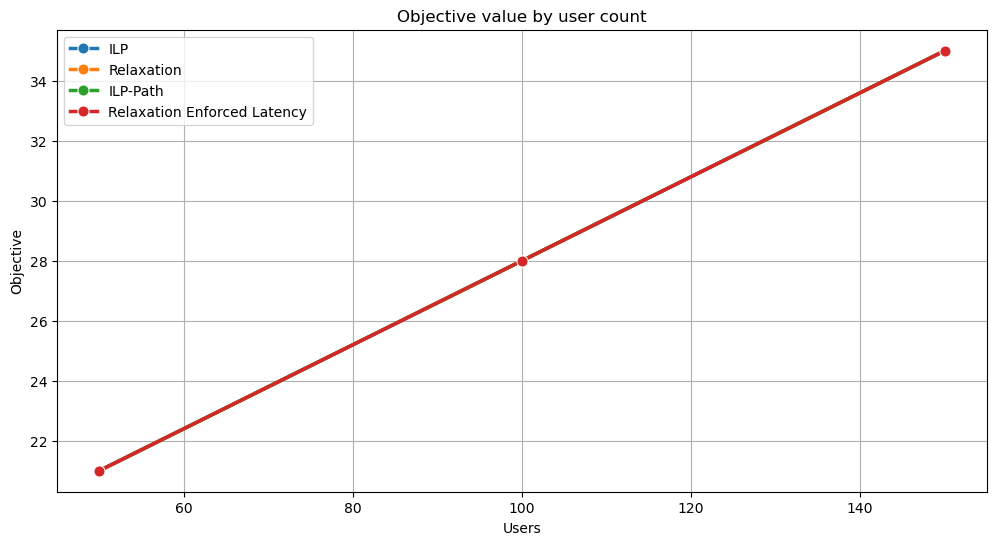

In [ ]:
import pandas as pd
import seaborn as sns
import numpy as np
from mecbench.instances.synthetic import make_tree_instance
from mecbench.solvers.exact.ilp_arc import Solver as ilp_arc_Solver
from mecbench.solvers.relaxations.lp_arc import Solver as lp_arc_Solver
from mecbench.solvers.exact.ilp_path import Solver as ilp_path_Solver
from mecbench.solvers.relaxations.lp_path_latency_tightened import Solver as lp_path_strong_latency_Solver

import matplotlib.pyplot as plt
import os
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"


# Create instances with 50, 100, and 150 users
instances = {
    50: make_tree_instance(50, 1),
    100: make_tree_instance(100, 1),
    150: make_tree_instance(150, 1)
}

results = []


mecbench.solvers = {'ILP': ilp_arc_Solver, 'Relaxation': lp_arc_Solver, 'ILP-Path': ilp_path_Solver, 'Relaxation Enforced Latency': lp_path_strong_latency_Solver}

for num_users, instance in instances.items():
    print(num_users)
    for sol_name, Solver in mecbench.solvers.items():
        sol = Solver(instance)
        sol.run()
        results.append({
            'Solver': sol_name,
            'Users': num_users,
            'Objective Value': sol.score,
            'Time': sol.runtime
        })

# Convert results to a DataFrame
results_df = pd.DataFrame(results)

common_params = {
    'linewidth': 2.5,  # Thicker lines
    'markersize': 8,   # Larger markers
    'ax': None
}

plt.figure(figsize=(12, 6))
sns.lineplot(data=results_df, x='Users', y='Objective Value', hue='Solver', marker='o', **common_params)
plt.title('Objective value by user count')
plt.ylabel('Objective')
plt.xlabel('Users')
plt.grid(True)
plt.legend()
plt.savefig('objective_bound.pdf')
plt.show()